## When the Load Changes Execution Times, and Two Ways to Keep the Bounds Valid

**Question.** The bounds of Pegasus assume that the execution time $Y$ of an item (s, from the start to the end of its
processing) depends only on the configuration of its service, and not on the *load*, i.e. on how many items arrive
(Assumption 3 of the paper). That assumption is what allows execution times measured in one composition to be reused
in another. A real service can violate it in two ways:

- **Throttling.** A container may use only a fixed amount of CPU time per scheduling period (its *CPU quota*, given
  in cores). Once the quota of a period is used up, the service stands still until the period ends. More items per
  second use more CPU time, so throttling depends on the load.
- **Warm-up.** A service that has been idle can be slower for its next item (e.g. cold caches), so an item's execution
  time depends on how long ago the previous item was processed, which again depends on the load.

This notebook shows both effects in the measurements of the testbed campaign (`statics/results_milos`), and
visualizes one remedy for each:

1. **Setup:** parameters and data.
2. **Remedy 1, provisioning:** give a service at least as many cores as its workers can use. Throttling then cannot
   occur at any load.
3. **Remedy 2, conservative benchmark:** measure the execution times in the state in which the service is slowest.
   A bound computed from them stays valid at every load.
4. **What follows for the paper.**

The measurements come from the campaign that releases the items of a service once per second; the helper functions
are in `pegasus/load_dependence.py`.

### 1. Setup

The parameters of the cell below:

- `alpha`: the violation probability $\varepsilon$; a bound at `alpha` is a latency (s) that an item exceeds with
  probability at most $\varepsilon$.
- `throttled_threshold`: a run counts as *throttled* if the service had used up its CPU quota in more than this share
  of the scheduling periods.
- `idle_s`: an item starts *after idle* if its service had processed nothing for longer than this (s).
- `back_to_back_s`: an item starts *back to back* if the item before it finished less than this (s) earlier.
- `window_s`: how busy a service is when an item arrives is measured by the number of arrivals at the service in the
  `window_s` (s) before that item.
- `p_label`: the name of the $(1-\varepsilon)$ quantile in the axis labels, e.g. $P_{95}$ for the 95th percentile.
- `seed`: seed of the two simulations (Sections 2b and 3b).

Two tables are loaded, both only from valid runs of the campaign:

- `runs`: one row per run of a service that was measured alone. *Workers* is the number of worker processes of the
  service (the knob `parallelism`); each worker processes one item at a time. *Cores* is the CPU quota of the container.
- `effects`: one row per run of a pipeline and service in it, computed from the per-item records of that run.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

from pegasus.load_dependence import simulate_cpu_quota, single_service_runs, warmup_bound_comparison, within_run_effects

alpha = 0.05                 # violation probability epsilon of a latency bound
throttled_threshold = 0.05   # a run is "throttled" if its quota was used up in more than this share of the scheduling periods
idle_s = 0.5                 # s; an item starts "after idle" if its service processed nothing for longer than this
back_to_back_s = 0.05        # s; an item starts "back to back" if the item before it finished less than this earlier
window_s = 2.0               # s; window before an arrival in which the arrivals at the service are counted (busy or calm)
seed = 0                     # seed of the simulations in 2b and 3b
p_label = f"$P_{{{100 * (1 - alpha):g}}}$"

plt.style.use('default')
plt.rcParams.update({'font.size': 12})

# Source: statics/results_milos (dataset.csv of every experiment, trace_steps.csv of every pipeline run)
runs = single_service_runs()                 # services measured alone: one row per run
effects = within_run_effects(idle_s=idle_s, back_to_back_s=back_to_back_s, window_s=window_s)   # pipelines: one row per run and service
print(f"{len(runs)} runs of {runs['service'].nunique()} services measured alone; "
      f"{len(effects)} combinations of a pipeline run and a service, from {effects['experiment'].nunique()} pipeline experiments.")
if effects.attrs["cut_off"]:
    print("Left out, because their dataset.csv is cut off:", ", ".join(effects.attrs["cut_off"]))

666 runs of 14 services measured alone; 7528 combinations of a pipeline run and a service, from 15 pipeline experiments.


### 2. Remedy 1: Provision Enough Cores for the Workers

#### 2a. When does a service get throttled?

**Claim.** Throttling is decided by the configuration and not by the load, as long as the service has more cores than
workers: a service with fewer workers than cores is never throttled, however much of its quota it uses.

**The figure below** has one point per run of a service measured alone. The vertical axis of both panels is the share
of the scheduling periods of the run in which the service had used up its CPU quota (0 = never throttled).
- *Left:* against the number of workers ÷ the number of cores of the run (points are spread slightly sideways so that
  they do not hide each other). The vertical line marks workers = cores.
- *Right:* against the share of the CPU quota that the run used on average (CPU time used ÷ CPU time allowed), which
  grows with the arrival rate. The three groups of the legend are the runs with fewer workers than cores, with as many
  workers as cores, and with more workers than cores.

What to look at: left, whether any point left of the vertical line lies above 0; right, whether the group with fewer
workers than cores stays at 0 while the other two rise with the used share of the quota.

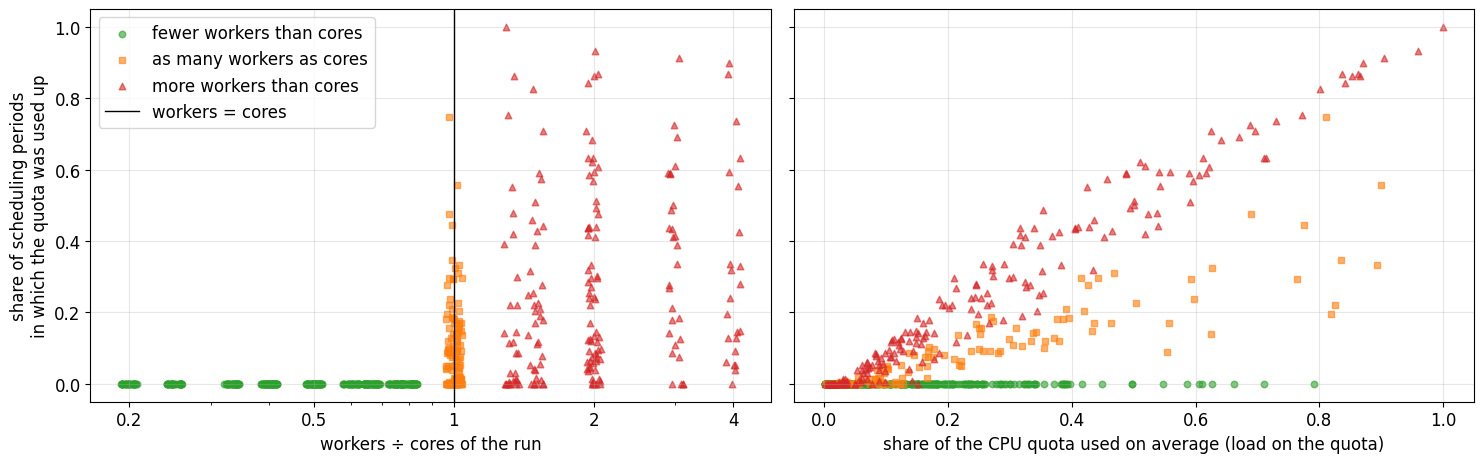

In [2]:
# Source: statics/results_milos, experiments "*-single-*" (dataset.csv), valid runs
ratio = runs["workers"] / runs["cores"]
groups = {"fewer workers than cores": (ratio < 1, "tab:green", "o"),
          "as many workers as cores": (ratio == 1, "tab:orange", "s"),
          "more workers than cores": (ratio > 1, "tab:red", "^")}
rng_jitter = np.random.default_rng(seed)

fig, (left, right) = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
for name, (chosen, color, marker) in groups.items():
    left.scatter(ratio[chosen] * np.exp(rng_jitter.uniform(-0.04, 0.04, chosen.sum())), runs["throttled"][chosen], s=22, alpha=0.6, color=color, marker=marker, label=name)
    right.scatter(runs["cpu_use"][chosen], runs["throttled"][chosen], s=22, alpha=0.6, color=color, marker=marker, label=name)
left.axvline(1.0, color="black", linewidth=1, label="workers = cores")
left.set_xscale("log")
left.set_xticks([0.2, 0.5, 1, 2, 4], labels=["0.2", "0.5", "1", "2", "4"])
left.set_xlabel("workers ÷ cores of the run")
left.set_ylabel("share of scheduling periods\nin which the quota was used up")
right.set_xlabel("share of the CPU quota used on average (load on the quota)")
for axis in (left, right):
    axis.grid(alpha=0.3)
left.legend(loc="upper left")
plt.tight_layout()
plt.show()

In [3]:
throttled = runs["throttled"] > throttled_threshold
share = lambda chosen: f"{np.mean(throttled[chosen]):.0%} of {chosen.sum()} runs"
cores_per_worker = runs["cores_per_busy_worker"].median()
display(Markdown(
    f"**What this shows.** A run counts as throttled if its quota was used up in more than {throttled_threshold:.0%} of the scheduling periods.\n"
    f"- **Fewer workers than cores:** {share(ratio < 1)} are throttled, although these runs use up to "
    f"{runs['cpu_use'][ratio < 1].max():.0%} of their quota.\n"
    f"- **As many workers as cores:** {share(ratio == 1)}. **More workers than cores:** {share(ratio > 1)}. In both groups the throttled share of the "
    f"periods rises with the used share of the quota, i.e. with the load.\n"
    f"- **Why \"as many workers as cores\" is not enough:** a busy worker uses {cores_per_worker:.2f} cores in the median over all runs (CPU time used ÷ "
    f"time its workers spent processing), slightly more than one, so a service whose workers are all busy exceeds a quota of one core per worker. "
    f"The rule therefore needs some slack: cores ≥ workers × cores that one busy worker uses."))

**What this shows.** A run counts as throttled if its quota was used up in more than 5% of the scheduling periods.
- **Fewer workers than cores:** 0% of 349 runs are throttled, although these runs use up to 79% of their quota.
- **As many workers as cores:** 50% of 129 runs. **More workers than cores:** 76% of 188 runs. In both groups the throttled share of the periods rises with the used share of the quota, i.e. with the load.
- **Why "as many workers as cores" is not enough:** a busy worker uses 1.07 cores in the median over all runs (CPU time used ÷ time its workers spent processing), slightly more than one, so a service whose workers are all busy exceeds a quota of one core per worker. The rule therefore needs some slack: cores ≥ workers × cores that one busy worker uses.

#### 2b. What throttling does to the execution time, and why the rule removes it

**Claim.** Throttling makes the slowest items of a run much slower, and it makes the execution time depend on the load.
With enough cores for all workers, the execution time is the same at every load.

**The figure below** has two panels.
- *Left (measured):* one point per run of a service measured alone. Horizontal axis: the share of the scheduling
  periods in which the quota was used up, as in 2a. Vertical axis (logarithmic): the 95th percentile ÷ the median of
  the processing times of the run, i.e. how much slower the slow items of that run are than a typical one. The black
  line is the median of the points in each range of the horizontal axis (`edges` in the code).
- *Right (simulated):* a pool of `sim_workers` workers under a CPU quota (`simulate_cpu_quota`), once with fewer cores than its workers can use and once with as many (`pools` in the code). In the simulation a busy worker uses exactly
  `sim_cores_per_worker` core, and an item needs `sim_mean` s of undisturbed processing on average. Horizontal axis:
  the offered load $\lambda \cdot$ `sim_mean`, the average number of workers that are busy ($\lambda$: arrival rate,
  items/s). Vertical axis: the execution time (ms) of an item from its start to its end, including the time its
  worker stood still; solid lines are the 95th percentile, dotted lines the median.

What to look at: left, whether the black line rises; right, whether the lines of the pool with enough cores stay flat
while those of the pool with too few cores rise with the load.

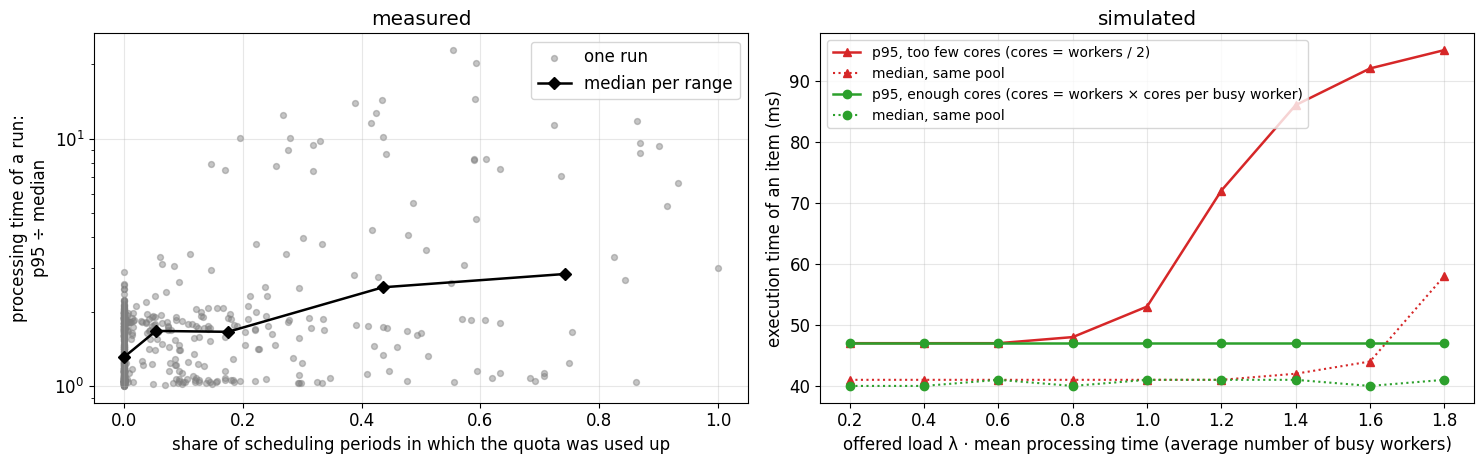

In [4]:
# Simulated pool: 4 workers that use one core each while busy; the quota is 2 cores (too few) or 4 cores (enough for all workers)
sim_workers, sim_cores_per_worker = 4, 1.0
sim_mean, sim_sd = 0.040, 0.004                  # s; undisturbed processing time of an item (Gaussian)
sim_duration = 240.0                             # s of simulated time per load
offered = np.arange(0.2, 1.81, 0.2)              # offered load lambda * sim_mean: average number of busy workers
pools = {"too few cores (cores = workers / 2)": (sim_workers * sim_cores_per_worker / 2, "tab:red", "^"),
         "enough cores (cores = workers × cores per busy worker)": (sim_workers * sim_cores_per_worker, "tab:green", "o")}
rng_quota = np.random.default_rng([seed, 1])
quota_results = {name: [simulate_cpu_quota(sim_workers, sim_cores_per_worker, cores, load / sim_mean, sim_mean, sim_sd, sim_duration, rng_quota)
                        for load in offered] for name, (cores, _, _) in pools.items()}

fig, (left, right) = plt.subplots(1, 2, figsize=(15, 4.8))
# Left, source: statics/results_milos, experiments "*-single-*" (dataset.csv), valid runs
left.scatter(runs["throttled"], runs["tail_ratio"], s=18, alpha=0.45, color="tab:gray", label="one run")
edges = [0, 0.01, 0.1, 0.3, 0.6, 1.0]
bins = np.digitize(runs["throttled"], edges[1:-1], right=True)
bin_medians = [runs["tail_ratio"][bins == b].median() for b in range(len(edges) - 1)]
left.plot([runs["throttled"][bins == b].median() for b in range(len(edges) - 1)], bin_medians, "k-D", linewidth=1.8, label="median per range")
left.set_yscale("log")
left.set_xlabel("share of scheduling periods in which the quota was used up")
left.set_ylabel(f"processing time of a run:\n{p_label} ÷ median")
left.set_title("measured")
left.legend()
for name, (_, color, marker) in pools.items():
    right.plot(offered, [1e3 * np.quantile(times, 1 - alpha) for times, _ in quota_results[name]], color=color, marker=marker, linewidth=1.8, label=f"{p_label}, {name}")
    right.plot(offered, [1e3 * np.median(times) for times, _ in quota_results[name]], color=color, marker=marker, linewidth=1.5, linestyle=":", label="median, same pool")
right.set_xlabel("offered load λ · mean processing time (average number of busy workers)")
right.set_ylabel("execution time of an item (ms)")
right.set_title("simulated")
right.legend(fontsize=10)
for axis in (left, right):
    axis.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [5]:
p_of = lambda name, i: np.quantile(quota_results[name][i][0], 1 - alpha)
few, enough = pools
display(Markdown(
    f"**What this shows.**\n"
    f"- **Measured:** in runs that were throttled in at most {edges[1]:.0%} of the periods, the {p_label} of the processing time is "
    f"{bin_medians[0]:.1f}× the median; in runs throttled in more than {edges[-2]:.0%} of the periods it is {bin_medians[-1]:.1f}×. Throttling "
    f"lengthens the slow items, which is the part of the distribution that a latency bound at a small ε depends on.\n"
    f"- **Simulated, too few cores:** the {p_label} of the execution time grows from {1e3 * p_of(few, 0):.0f} ms at an offered load of {offered[0]:.1f} "
    f"to {1e3 * p_of(few, -1):.0f} ms at {offered[-1]:.1f}, and the pool is throttled in {quota_results[few][-1][1]:.0%} of the periods there. The reason: "
    f"the more workers are busy at once, the earlier in a period the quota of {pools[few][0]:g} cores is used up.\n"
    f"- **Simulated, enough cores:** the {p_label} is {1e3 * p_of(enough, 0):.0f} ms at the lowest and {1e3 * p_of(enough, -1):.0f} ms at the highest "
    f"of the same loads, and the pool is never throttled "
    f"(largest throttled share: {max(result[1] for result in quota_results[enough]):.0%}). The reason holds for any load: even when all workers are "
    f"busy for a whole period, they cannot use more CPU time than the quota allows."))

**What this shows.**
- **Measured:** in runs that were throttled in at most 1% of the periods, the p95 of the processing time is 1.3× the median; in runs throttled in more than 60% of the periods it is 2.8×. Throttling lengthens the slow items, which is the part of the distribution that a latency bound at a small ε depends on.
- **Simulated, too few cores:** the p95 of the execution time grows from 47 ms at an offered load of 0.2 to 95 ms at 1.8, and the pool is throttled in 70% of the periods there. The reason: the more workers are busy at once, the earlier in a period the quota of 2 cores is used up.
- **Simulated, enough cores:** the p95 is 47 ms at the lowest and 47 ms at the highest of the same loads, and the pool is never throttled (largest throttled share: 0%). The reason holds for any load: even when all workers are busy for a whole period, they cannot use more CPU time than the quota allows.

### 3. Remedy 2: Benchmark in the Slowest State

#### 3a. In which state is a service slowest?

**Claim.** Without throttling, an item is not slowed down by other items that are processed at the same time, but a
service is slower right after an idle period. A service is therefore slowest at *low* load.

Every comparison is made within one run of a pipeline, i.e. at one fixed configuration, between items of the same
service. An item is grouped by what its service did when the item started: *next to another* (another worker of the
service was still processing an item), *back to back* (the previous item finished less than `back_to_back_s` earlier), or
*after idle* (nothing was processed for longer than `idle_s`). A ratio of 1 means no difference.

**The figure below** has two panels.
- *Left:* three ratios of median processing times, each as a box over all combinations of a run and a service
  (box: first to third quartile; line in the box: median; whiskers: 5th to 95th percentile). From top to bottom:
  items *next to another* ÷ items *back to back*; items *after idle* ÷ items *back to back*; and the third of the items
  of a run that arrived while the service was busiest ÷ the third that arrived while it was calmest (measured by the
  number of arrivals at the service in the `window_s` before the item). The horizontal axis is logarithmic; the vertical line
  marks a ratio of 1.
- *Right:* the ratio *after idle* ÷ *back to back* per service (median over the runs of the service), sorted.

What to look at: on which side of the vertical line each box lies.

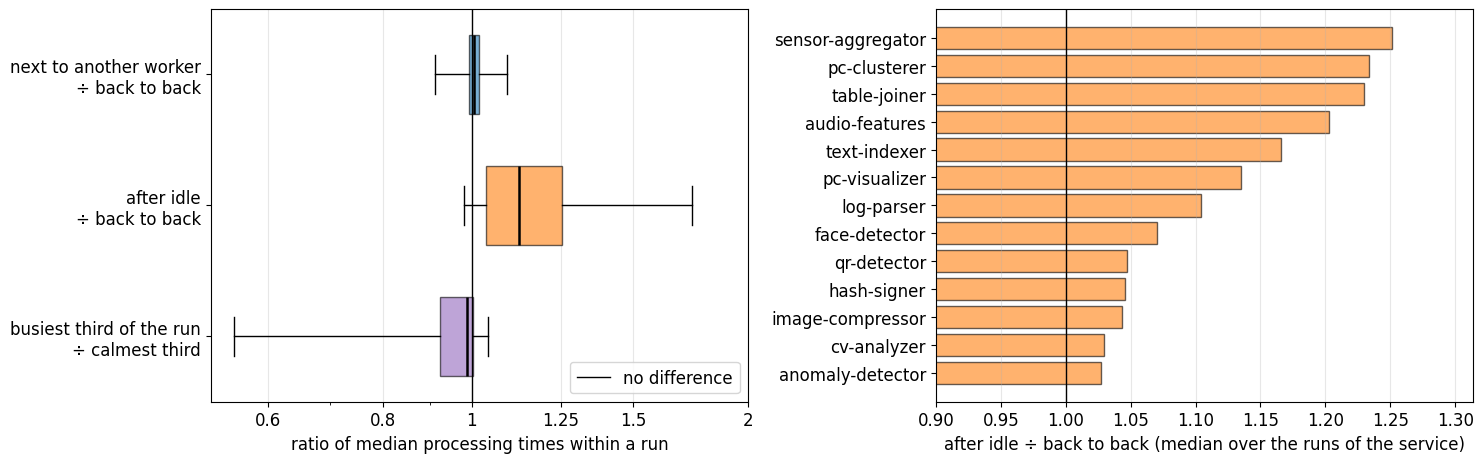

In [6]:
# Source: statics/results_milos, trace_steps.csv of every valid pipeline run (table `effects` of the setup cell)
comparisons = {"next to another worker\n÷ back to back": ("next_to_another", "tab:blue"),
               "after idle\n÷ back to back": ("after_idle", "tab:orange"),
               "busiest third of the run\n÷ calmest third": ("busy_vs_calm", "tab:purple")}
per_service = effects.groupby("service")["after_idle"].median().sort_values()

fig, (left, right) = plt.subplots(1, 2, figsize=(15, 4.8))
values = [effects[column].dropna() for column, _ in comparisons.values()]
boxes = left.boxplot(values[::-1], vert=False, whis=(5, 95), showfliers=False, patch_artist=True, widths=0.6,
                     medianprops=dict(color="black", linewidth=1.8))
for box, (_, color) in zip(boxes["boxes"], list(comparisons.values())[::-1]):
    box.set(facecolor=color, alpha=0.6)
left.set_yticks(range(1, len(comparisons) + 1), labels=list(comparisons)[::-1])
left.axvline(1.0, color="black", linewidth=1, label="no difference")
left.set_xscale("log")
left.set_xticks([0.6, 0.8, 1, 1.25, 1.5, 2], labels=["0.6", "0.8", "1", "1.25", "1.5", "2"])
left.set_xlabel("ratio of median processing times within a run")
left.legend(loc="lower right")
right.barh([name.split(":")[0] for name in per_service.index], per_service.values, color="tab:orange", alpha=0.6, edgecolor="black")
right.axvline(1.0, color="black", linewidth=1)
right.set_xlim(0.9, None)
right.set_xlabel("after idle ÷ back to back (median over the runs of the service)")
for axis in (left, right):
    axis.grid(alpha=0.3, axis="x")
plt.tight_layout()
plt.show()

In [7]:
quartiles = lambda column: (f"{effects[column].median():.2f} in the median (quartiles {effects[column].quantile(0.25):.2f} to "
                            f"{effects[column].quantile(0.75):.2f}, {effects[column].notna().sum()} combinations)")
display(Markdown(
    f"**What this shows.**\n"
    f"- **Next to another worker:** the ratio is {quartiles('next_to_another')}. Two workers that process at the same time do not slow each other "
    f"down in these runs (the pipelines of the campaign have at most {effects['workers'].max()} workers per service).\n"
    f"- **After idle:** the ratio is {quartiles('after_idle')}, and above 1 in {np.mean(effects['after_idle'].dropna() > 1):.0%} of the combinations. "
    f"The effect differs between services, from {per_service.iloc[0]:.2f} ({per_service.index[0].split(':')[0]}) to {per_service.iloc[-1]:.2f} "
    f"({per_service.index[-1].split(':')[0]}).\n"
    f"- **Busy against calm phases of a run:** the ratio is {quartiles('busy_vs_calm')}; it is below 1 in "
    f"{np.mean(effects['busy_vs_calm'] < 1):.0%} of the combinations. Under more load an item is, if anything, faster, because fewer items start after "
    f"an idle period.\n\n"
    f"The slowest state of a service is therefore the idle one. In this campaign the items of a service are released once per second, so "
    f"\"after idle\" mostly means the first item of such a release."))

**What this shows.**
- **Next to another worker:** the ratio is 1.00 in the median (quartiles 0.99 to 1.02, 1902 combinations). Two workers that process at the same time do not slow each other down in these runs (the pipelines of the campaign have at most 2 workers per service).
- **After idle:** the ratio is 1.12 in the median (quartiles 1.04 to 1.25, 7330 combinations), and above 1 in 92% of the combinations. The effect differs between services, from 1.03 (anomaly-detector) to 1.25 (sensor-aggregator).
- **Busy against calm phases of a run:** the ratio is 0.99 in the median (quartiles 0.92 to 1.00, 7528 combinations); it is below 1 in 69% of the combinations. Under more load an item is, if anything, faster, because fewer items start after an idle period.

The slowest state of a service is therefore the idle one. In this campaign the items of a service are released once per second, so "after idle" mostly means the first item of such a release.

#### 3b. What the benchmark state means for a bound

**Claim.** A bound that is computed from execution times measured in the slowest state (one item at a time, each after
an idle period) holds at every load and for any size of the warm-up effect. A bound computed from a benchmark at full
load holds only as long as its own slack is larger than the warm-up effect.

**Why.** In a queue with one worker, an item cannot leave later if any execution time becomes shorter. If every
execution time in deployment is at most as long as in the benchmark state, the latencies in deployment are at most
those of a queue in which every item takes its benchmark time, and the bound for that queue also holds in deployment.
The argument needs "at most as long", not "equal": this is the weaker form of Assumption 3.

**The simulation** (`warmup_bound_comparison`) is one service with one worker and Poisson arrivals at rate $\lambda$
(items/s). An item that starts right after another one takes a Gaussian time with mean `warm_mean` (s); an item that
starts after more than `idle_s` of idleness takes *warm-up factor* times as long. Two benchmarks of this service are
simulated, and each gives a mean and a variance of the execution time:
- *isolated:* one item at a time with idle gaps longer than `idle_s`, so every item is slow;
- *saturated:* all items available at once, so every item except the first starts right after another one.

From each benchmark, the latency bound of Pegasus for one service is computed for every arrival rate
(`martingale_closed_form_node_bound`: Kingman's bound on the waiting time plus the item's own execution time), and
compared with the measured $(1-\varepsilon)$ quantile of the latency $L$ (s; waiting time + execution time).

**The figure below** has two panels.
- *Left:* the warm-up factor is that of the campaign's service with the strongest warm-up effect (the top bar of the
  right panel in 3a). Horizontal axis (logarithmic): the arrival rate $\lambda$. Vertical axis (logarithmic): the
  measured quantile and the two bounds. A bound is valid where its line lies above the measured one; a bound line ends
  where the bound is infinite, i.e. where the service would be overloaded if every item took its benchmark time.
- *Right:* the same comparison for warm-up factors from 1 (no warm-up effect) upward. Vertical axis: the smallest
  value of bound ÷ measured quantile over all arrival rates at which the bound is finite, i.e. the bound at the rate
  where it is closest to failing. Below the horizontal line at 1 the bound fails at some arrival rate. The shaded
  range marks the warm-up factors of the campaign's services (the bars of 3a).

What to look at: right, which of the two lines crosses below 1, and where that crossing lies relative to the shaded
range.

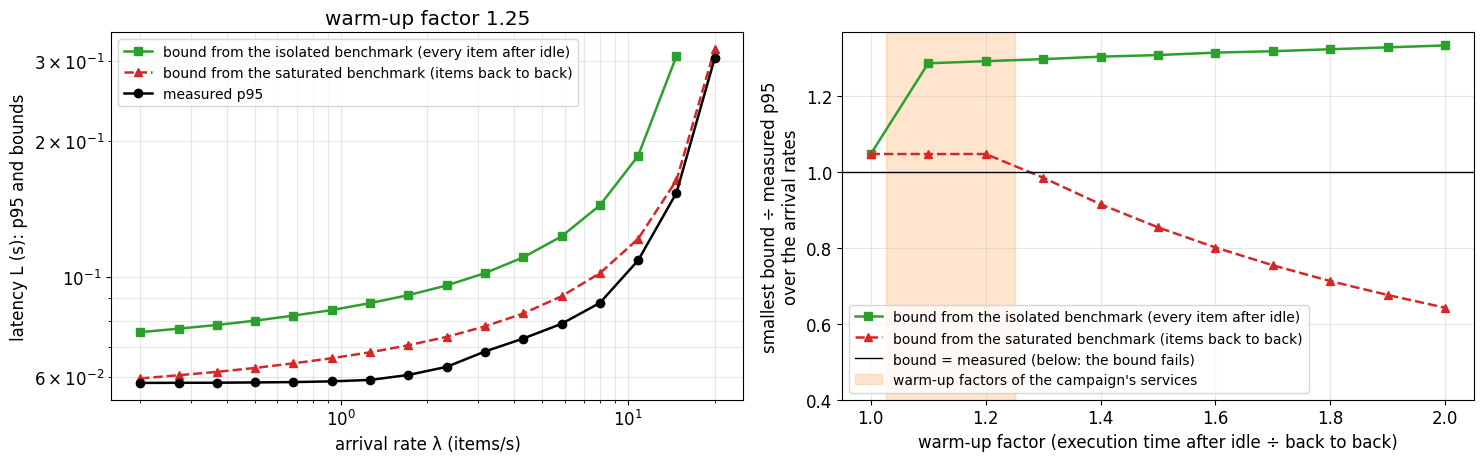

In [8]:
# One service with one worker and a warm-up effect; bounds from an isolated and from a saturated benchmark of that service
warm_mean, warm_sd = 0.040, 0.004                       # s; execution time of an item that starts right after another one (Gaussian)
rates = np.geomspace(0.2, 0.8 / warm_mean, 16)          # arrival rates lambda (items/s); the largest gives a utilization of 0.8 for warm items
strongest_factor = per_service.iloc[-1]                 # the campaign's service with the strongest warm-up effect (3a)
warmup_factors = np.round(np.arange(1.0, 2.01, 0.1), 2) # execution time after idle / execution time back to back
simulation = dict(rates=rates, warm_mean=warm_mean, warm_sd=warm_sd, idle_s=idle_s, epsilon=alpha, n_deployed=100_000, n_benchmark=5_000, seed=[seed, 2])
reference = warmup_bound_comparison(strongest_factor, **simulation)
sweep = {factor: warmup_bound_comparison(factor, **simulation) for factor in warmup_factors}

def worst_ratio(result, benchmark):   # smallest bound / measured quantile over the rates at which the bound is finite
    finite = np.isfinite(result["bounds"][benchmark])
    return np.min(result["bounds"][benchmark][finite] / result["measured"][finite])

styles = {"isolated": ("isolated benchmark (every item after idle)", "tab:green", "-", "s"),
          "saturated": ("saturated benchmark (items back to back)", "tab:red", "--", "^")}
fig, (left, right) = plt.subplots(1, 2, figsize=(15, 4.8))
for benchmark, (name, color, style, marker) in styles.items():
    left.plot(rates, reference["bounds"][benchmark], color=color, linestyle=style, marker=marker, linewidth=1.8, label=f"bound from the {name}")
    right.plot(warmup_factors, [worst_ratio(sweep[factor], benchmark) for factor in warmup_factors], color=color, linestyle=style, marker=marker,
               linewidth=1.8, label=f"bound from the {name}")
left.plot(rates, reference["measured"], "k-o", linewidth=1.8, label=f"measured {p_label}")
left.set_xscale("log")
left.set_yscale("log")
left.set_xlabel("arrival rate λ (items/s)")
left.set_ylabel(f"latency L (s): {p_label} and bounds")
left.set_title(f"warm-up factor {strongest_factor:.2f}")
right.axhline(1.0, color="black", linewidth=1, label="bound = measured (below: the bound fails)")
right.axvspan(per_service.iloc[0], per_service.iloc[-1], color="tab:orange", alpha=0.2, label="warm-up factors of the campaign's services")
right.set_xlabel("warm-up factor (execution time after idle ÷ back to back)")
right.set_ylabel(f"smallest bound ÷ measured {p_label}\nover the arrival rates")
right.set_ylim(0.4, None)   # room for the legend below the lines
left.legend(fontsize=10, loc="upper left")
right.legend(fontsize=10, loc="lower left")
for axis in (left, right):
    axis.grid(alpha=0.3, which="both")
plt.tight_layout()
plt.show()

In [9]:
finite = np.isfinite(reference["bounds"]["isolated"])
worst = {benchmark: np.array([worst_ratio(sweep[factor], benchmark) for factor in warmup_factors]) for benchmark in styles}
failing = warmup_factors[worst["saturated"] < 1]
last = sweep[warmup_factors[-1]]
worst_rate = rates[np.argmin(last["bounds"]["saturated"] / last["measured"])]   # arrival rate at which the saturated bound is furthest below
display(Markdown(
    f"**What this shows** (ε = {alpha:g}; a warm item takes {1e3 * warm_mean:.0f} ms on average).\n"
    f"- **Deployment at the warm-up factor {strongest_factor:.2f}:** at {rates[0]:.1f} items/s, {reference['cold_share'][0]:.0%} of the items start after an "
    f"idle period; at {rates[-1]:.0f} items/s it is {reference['cold_share'][-1]:.0%}. The isolated benchmark measures a mean execution time of "
    f"{1e3 * reference['benchmark_mean']['isolated']:.0f} ms, the saturated one {1e3 * reference['benchmark_mean']['saturated']:.0f} ms.\n"
    f"- **Bound from the isolated benchmark:** its smallest ratio to the measured {p_label} stays between {worst['isolated'].min():.2f} and "
    f"{worst['isolated'].max():.2f} over all warm-up factors, so it never fails; a larger warm-up effect raises the benchmark by the same factor. "
    f"Its price at the factor {strongest_factor:.2f}: it is {np.median((reference['bounds']['isolated'] / reference['measured'])[finite]):.2f}× the measured "
    f"{p_label} in the median over the rates (the saturated one: {np.median(reference['bounds']['saturated'] / reference['measured']):.2f}×), and it is "
    f"infinite at {np.sum(~finite)} of the {len(rates)} rates, at the upper end.\n"
    f"- **Bound from the saturated benchmark:** at the factor {strongest_factor:.2f} its smallest ratio is {worst_ratio(reference, 'saturated'):.2f}. "
    + (f"It fails from a warm-up factor of {failing.min():.1f} on (smallest ratio {worst['saturated'].min():.2f} at {warmup_factors[-1]:.1f}, reached at "
       f"{worst_rate:.1f} items/s), i.e. at low load, where most items are slower than any item the benchmark saw. Below that factor the bound holds only because "
       f"Kingman's bound has slack at low load, not because of an argument. Of the combinations of a run and a service in 3a, "
       f"{np.mean(effects['after_idle'].dropna() >= failing.min()):.0%} have a ratio after idle ÷ back to back at or above that factor."
       if len(failing) else "It does not fail for any factor shown: its slack is larger than the warm-up effect.")))

**What this shows** (ε = 0.05; a warm item takes 40 ms on average).
- **Deployment at the warm-up factor 1.25:** at 0.2 items/s, 90% of the items start after an idle period; at 20 items/s it is 0%. The isolated benchmark measures a mean execution time of 50 ms, the saturated one 40 ms.
- **Bound from the isolated benchmark:** its smallest ratio to the measured p95 stays between 1.05 and 1.33 over all warm-up factors, so it never fails; a larger warm-up effect raises the benchmark by the same factor. Its price at the factor 1.25: it is 1.49× the measured p95 in the median over the rates (the saturated one: 1.12×), and it is infinite at 1 of the 16 rates, at the upper end.
- **Bound from the saturated benchmark:** at the factor 1.25 its smallest ratio is 1.02. It fails from a warm-up factor of 1.3 on (smallest ratio 0.64 at 2.0, reached at 0.2 items/s), i.e. at low load, where most items are slower than any item the benchmark saw. Below that factor the bound holds only because Kingman's bound has slack at low load, not because of an argument. Of the combinations of a run and a service in 3a, 21% have a ratio after idle ÷ back to back at or above that factor.

### 4. What Follows for the Paper

Both remedies turn a statement about the load into a statement about how a service is configured and measured, which
is what a bound for an unseen composition needs:

- **Assumption 1 (performance isolation)** can carry the provisioning rule: a service has at least as many cores as
  its workers can use at once (cores ≥ workers × cores that one busy worker uses). Section 2 shows that throttling then
  does not occur at any load, and that without the rule it lengthens exactly the slow items that a bound depends on.
- **Assumption 3 (load-independent execution times)** can be weakened from "the execution time does not depend on the
  load" to "the execution time in deployment is at most as long as in the benchmark". Section 3 shows that the slowest
  state of a service is the idle one, so a benchmark of isolated items fulfills the weaker form, at the price of a looser
  bound at high load. A benchmark at full load holds only through the slack of the bound.

**Both remedies are needed, and the first one is a precondition for the second.** Each remedy removes one effect, and
neither removes the other one:
- *Enough cores do not remove the warm-up effect.* Warm-up does not come from the CPU quota: services that were not
  throttled are also slower after an idle period (output below).
- *A benchmark of isolated items does not cover throttling.* The two effects make a service slowest in opposite
  states: warm-up at low load, where the service is often idle; throttling at high load, where many workers use up the
  quota together. No single benchmark state is then the slowest for every item, which is what the argument of 3b needs.
  A benchmark that combined the worst of both (cold items under throttling) would have the heavy tail of 2b and give a
  very loose bound.

Only once the first remedy has removed throttling is the idle state the slowest state of a service, and only then
does a benchmark of isolated items give execution times that are at least as long as in deployment.

In [10]:
# Is the warm-up effect of 3a a consequence of throttling? Compare it between pipeline runs with and without throttling.
quota_groups = {"not throttled": effects["throttled"] <= throttled_threshold, "throttled": effects["throttled"] > throttled_threshold}
after_idle = {name: effects.loc[chosen, "after_idle"].dropna() for name, chosen in quota_groups.items()}
display(Markdown(
    f"**Warm-up with and without throttling** (throttled: quota used up in more than {throttled_threshold:.0%} of the scheduling periods).\n"
    + "\n".join(f"- **{name.capitalize()}:** after idle ÷ back to back is {ratios.median():.2f} in the median (quartiles {ratios.quantile(0.25):.2f} to "
                f"{ratios.quantile(0.75):.2f}) and above 1 in {np.mean(ratios > 1):.0%} of {len(ratios)} combinations of a run and a service."
                for name, ratios in after_idle.items())
    + ("\n\nThe warm-up effect is present without throttling, so the provisioning rule of Section 2 does not remove it."
       if after_idle["not throttled"].median() > 1 else
       "\n\nWithout throttling the median ratio is not above 1: the claim of the paragraph above does not hold for these data.")))

**Warm-up with and without throttling** (throttled: quota used up in more than 5% of the scheduling periods).
- **Not throttled:** after idle ÷ back to back is 1.13 in the median (quartiles 1.04 to 1.28) and above 1 in 92% of 5961 combinations of a run and a service.
- **Throttled:** after idle ÷ back to back is 1.09 in the median (quartiles 1.03 to 1.18) and above 1 in 92% of 1369 combinations of a run and a service.

The warm-up effect is present without throttling, so the provisioning rule of Section 2 does not remove it.

Limits of what this notebook shows:
- The measurements are from the campaign that releases items once per second, and its pipelines have few workers per
  service (3a). Whether workers still do not slow each other down in larger pools, and how large the warm-up effect is
  when items are dispatched immediately, has to be checked on the new campaign.
- The argument of 3b is made for one worker. For a pool of workers it needs the same property (an item does not leave
  later if any execution time becomes shorter), which is not shown here.
- The comparisons of 3a are within a run; the services of one pipeline run are not independent of each other, so the
  quartiles describe the spread of the ratios and are not confidence intervals.